# 02 — Strategy backtest (Phase 4)

**Design period only (2024-08-01 to 2026-06-30).** Every number comes from `src/backtest/`
(`engine.py`, `costs.py`, `metrics.py`); this notebook only calls it and displays the results.

Rules (DECISIONS.md 2026-11-04 and 2026-11-08, all values in `config.yaml`):
signal = trailing 7-day mean of the known-at-t gap; enter when |signal| > 10% APR, short the
higher-funding venue and long the other; exit when |signal| < 3% APR or on a sign change;
spread stop at 100 bps against the entry spread, then no re-entry until the signal meets the exit
rule; $10,000 per leg, 3x leverage, one position per coin, up to 15; rebalance when a leg's margin
falls below 50% of its requirement ($1 fee, 2h delay); liquidation at per-venue maintenance
margins with a 100 bps penalty. Decisions at bar closes (every 4h before each coin's hourly
Hyperliquid history starts on 2026-04-09, hourly after), fills at the next bar's open, taker on
both legs. Returns are on total capital: $100,000 of margin plus a 50% buffer = $150,000.

**Two model variants** (DECISIONS.md 2026-11-08), everything else identical:

| | Liquidation checked on | Rebalance trigger base |
|---|---|---|
| as-specified (first run, kept as the record) | last-trade candle highs/lows | initial margin at entry |
| corrected | Binance mark klines (BN leg), Binance index klines as proxy for HL's mark (HL leg) | current requirement, qty x price / leverage |

The random-entry benchmark (200 seeds) is too slow to rerun here; its results are read from
`report/tables/backtest_summary.csv` (as-specified) and `backtest_corrected_summary.csv`, written by
`python -m src.backtest.engine --variant ...`. The as-specified figures saved earlier
(`report/figures/backtest_*.png`) are not overwritten; this notebook saves only
`backtest_corrected_*` and `backtest_comparison_*` figures.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import load_config, ROOT
from src.backtest import engine as E, metrics as M
from src.analysis import backtest_figures as F


def show(fig, path):
    """The src modules use the Agg backend: close the figure and display the PNG it saved."""
    plt.close(fig)
    display(Image(filename=str(path)))

base_cfg = load_config()
inputs = E.load_inputs(base_cfg)
runs = {}
for v in ("as_specified", "corrected"):
    cfg = E.variant_cfg(base_cfg, v)
    runs[v] = {"strategy": E.run(cfg, inputs), "zero_cost": E.run(E.zero_cost(cfg), inputs),
               "always_on": E.run(cfg, inputs, E.AlwaysOnPolicy(1))}
usd = "{:,.0f}".format
check = pd.read_csv(ROOT / "report/tables/backtest_summary.csv", index_col=0)
assert abs(M.summary(runs["as_specified"]["strategy"])["total_pnl"] - check.loc["total_pnl", "strategy"]) < 0.01

## 1. Headline metrics, side by side

Strategy against the benchmarks of `docs/plan.md` Phase 4 item 7: zero cost (same rules, no fees
or slippage), always-on (short Hyperliquid / long Binance in every coin for the whole period,
exits only on liquidation) and random entry (same number of trades, holding periods and sides per
coin at random times; mean and 5-95% range over 200 seeds).

In [2]:
summ = pd.read_csv(ROOT / "report/tables/backtest_comparison_summary.csv", index_col=0, header=[0, 1])
fmt = {r: "{:.2%}" for r in ["ann_return_total_capital", "ann_return_deployed", "max_drawdown_frac", "hit_rate"]}
fmt.update({r: "{:,.0f}" for r in ["total_pnl", "capital", "avg_deployed_capital", "max_drawdown_usd", "worst_trade"]})
fmt.update({r: "{:.2f}" for r in ["sharpe", "avg_hold_days"]})
fmt.update({r: "{:.1f}" for r in ["trades", "spread_stops", "liquidations", "rebalances"]})
summ.apply(lambda row: row.map(fmt.get(row.name, "{:.2f}").format), axis=1)

as_specified                                  \
                             strategy zero_cost always_on random_mean   
total_pnl                      -8,871        99   -10,928     -13,394   
capital                       150,000   150,000   150,000     150,000   
ann_return_total_capital       -3.09%     0.03%    -3.80%      -4.66%   
avg_deployed_capital           32,170    31,645    99,943      28,929   
ann_return_deployed           -14.40%     0.16%    -5.71%     -24.21%   
sharpe                          -2.02      0.02     -0.66       -2.29   
max_drawdown_usd               -8,878    -2,230   -12,527     -14,009   
max_drawdown_frac              -5.92%    -1.48%    -8.36%      -9.31%   
trades                          213.0     213.0      57.0       214.0   
hit_rate                       31.92%    76.53%    35.09%      17.95%   
avg_hold_days                   15.45     15.19     72.71       14.17   
worst_trade                    -1,657    -1,634    -1,884      -1,748   
spread_stops                      0.0       0.0       0.0         0.0   
liquidations                     45.0      45.0      57.0        28.6   
rebalances                      196.0     188.0     329.0       167.8   

                                               corrected                      \
                         random_p05 random_p95  strategy zero_cost always_on   
total_pnl                   -18,734     -7,485    -4,270     5,686   -17,037   
capital                     150,000    150,000   150,000   150,000   150,000   
ann_return_total_capital     -6.52%     -2.61%    -1.49%     1.98%    -5.93%   
avg_deployed_capital         27,778     30,027    33,934    33,934    99,924   
ann_return_deployed         -34.84%    -13.71%    -6.57%     8.75%    -8.90%   
sharpe                        -3.40      -1.16     -0.61      0.81     -0.70   
max_drawdown_usd            -18,838     -9,468    -8,881    -3,554   -19,175   
max_drawdown_frac           -12.54%     -6.18%    -5.77%    -2.27%   -12.80%   
trades                        214.0      214.0     213.0     213.0      60.0   
hit_rate                     14.49%     21.03%    34.74%    80.28%    30.00%   
avg_hold_days                 13.61      14.73     16.34     16.34     87.15   
worst_trade                  -2,593     -1,062    -1,657    -1,634    -2,125   
spread_stops                    0.0        0.0       0.0       0.0       0.0   
liquidations                   23.0       35.0      38.0      37.0      60.0   
rebalances                    149.9      185.0     313.0     315.0     557.0   

                                                            
                         random_mean random_p05 random_p95  
total_pnl                    -11,436    -17,098     -5,684  
capital                      150,000    150,000    150,000  
ann_return_total_capital      -3.98%     -5.95%     -1.98%  
avg_deployed_capital          30,987     29,753     32,067  
ann_return_deployed          -19.32%    -29.20%     -9.41%  
sharpe                         -2.06      -3.26      -0.92  
max_drawdown_usd             -12,225    -17,299     -7,779  
max_drawdown_frac             -8.11%    -11.52%     -5.15%  
trades                         214.0      214.0      214.0  
hit_rate                      19.94%     16.80%     23.39%  
avg_hold_days                  15.17      14.56      15.73  
worst_trade                   -1,650     -2,317     -1,034  
spread_stops                     0.0        0.0        0.0  
liquidations                    25.4       19.0       33.0  
rebalances                     232.9      189.9      282.1

## 2. P&L decomposition, side by side (the main exhibit)

Each trade's P&L is booked in separate components that sum exactly to its total: Hyperliquid
funding (every hour held), Binance funding (only at settlements while open), price spread (both
legs at unslipped fill prices), fees, slippage, collateral-transfer fees and liquidation penalties.
`price_unrealised` is any position still open at the end of the design period.

In [3]:
dec = pd.concat({v: pd.DataFrame({k: M.decomposition(r.trades).loc["ALL"] for k, r in rr.items()})
                 for v, rr in runs.items()}, axis=1)
liq = pd.concat({v: pd.Series({k: r.counters["liquidations"] for k, r in rr.items()})
                 for v, rr in runs.items()})
dec.loc["liquidations (count)"] = liq
dec.style.format(usd)

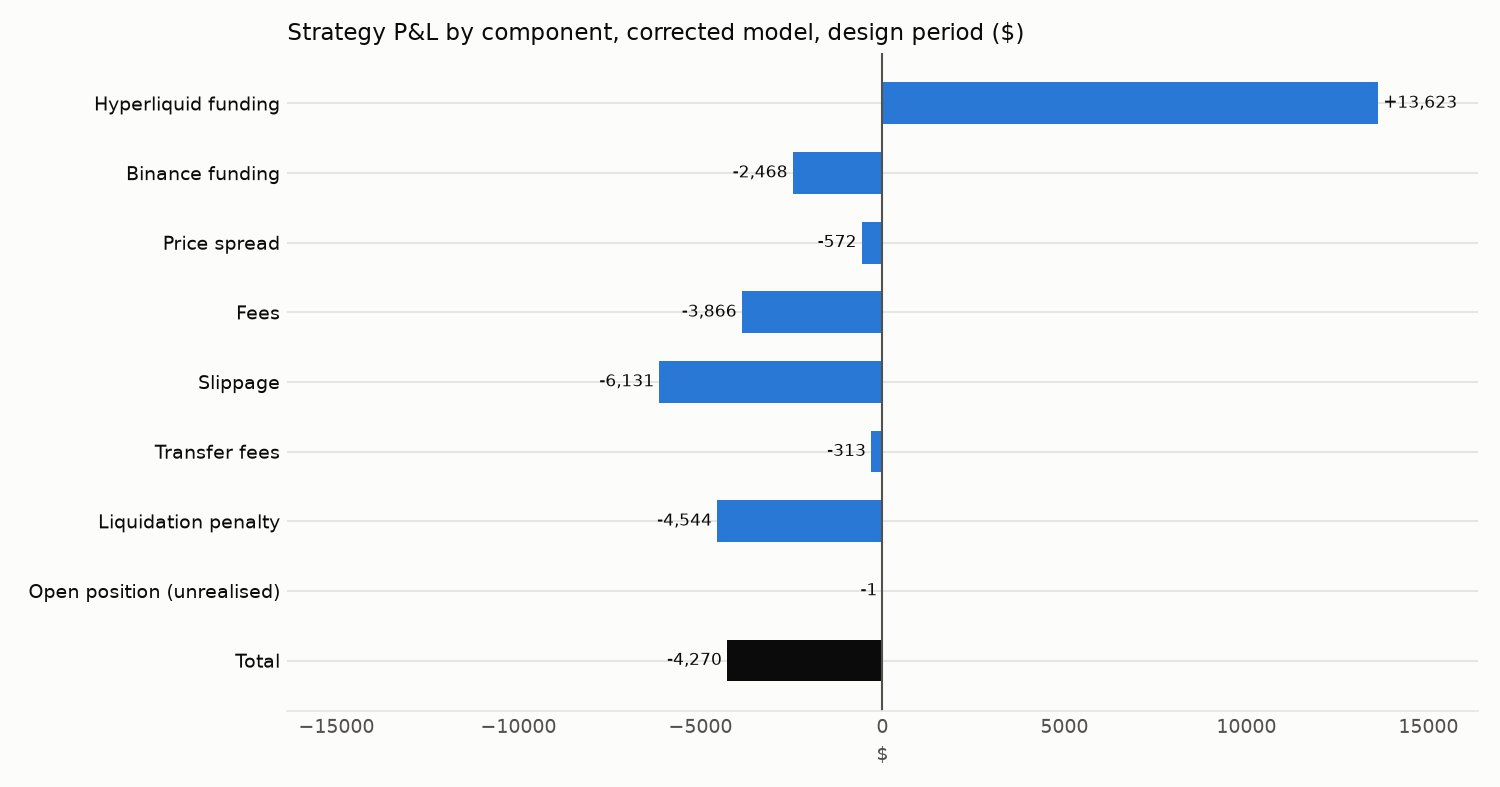

In [4]:
path = ROOT / "report/figures/backtest_corrected_decomposition.png"
show(F.plot_decomposition(M.decomposition(runs["corrected"]["strategy"].trades).loc["ALL"],
                     "Strategy P&L by component, corrected model, design period ($)",
                     path), path)

### Per coin (corrected)

In [5]:
M.decomposition(runs["corrected"]["strategy"].trades).style.format(usd)

,hl_funding,bn_funding,price_spread,fees,slippage,transfer_fees,liquidation,price_unrealised,total
coin,,,,,,,,,
TIA,78,443,-623,-305,-512,-13,-242,0,"-1,173"
SUI,866,-280,-749,-292,-492,-27,-458,0,"-1,433"
WLD,405,142,623,-354,-595,-31,-557,0,-368
kPEPE,"1,412",-171,"3,053",-303,-510,-31,-401,-1,"3,048"
AVAX,993,-236,"-1,362",-308,-519,-14,-211,0,"-1,657"
TAO,"1,235",-71,"-1,895",-290,-486,-22,-652,0,"-2,181"
kBONK,766,-175,-390,-305,-512,-24,-558,0,"-1,199"
APT,495,-28,791,-351,-592,-15,-241,0,59
SOL,"1,682",-552,"-1,130",-228,-384,-54,-67,0,-734


## 3. Equity curves

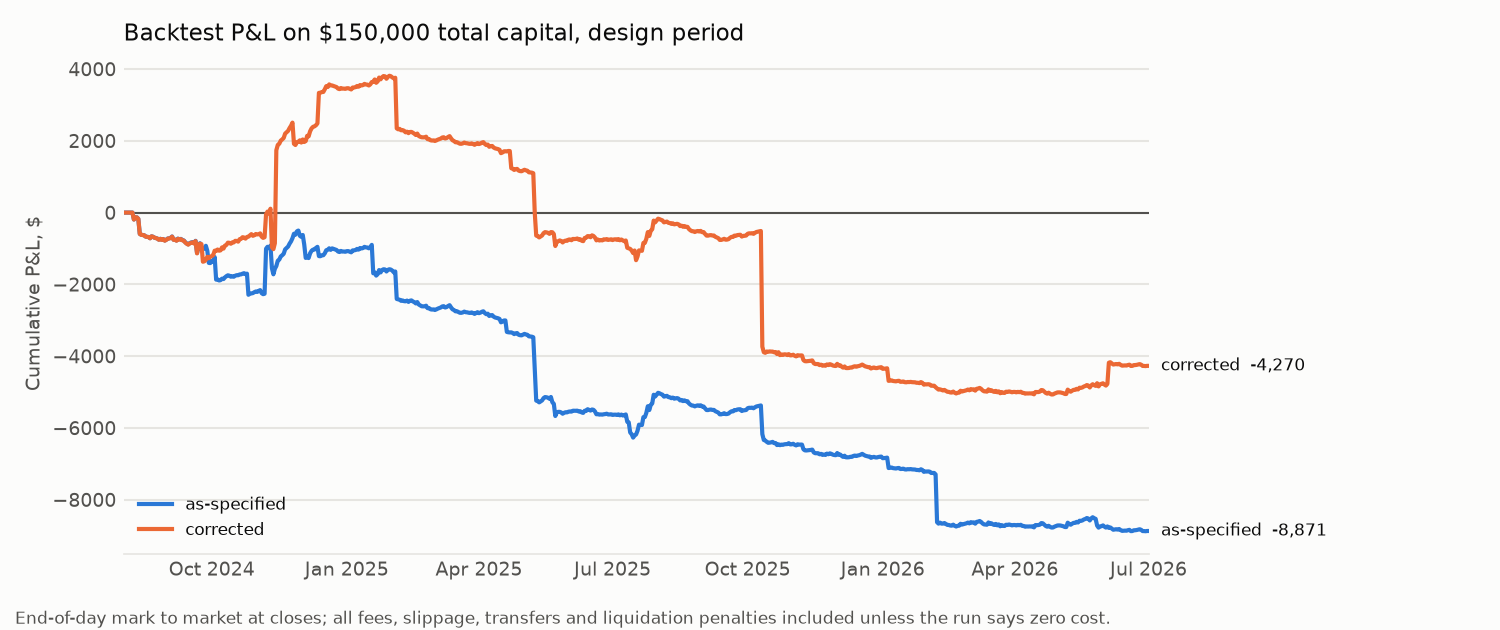

In [6]:
path = ROOT / "report/figures/backtest_comparison_equity.png"
show(F.plot_equity({"as-specified": runs["as_specified"]["strategy"].daily,
               "corrected": runs["corrected"]["strategy"].daily},
              E.total_capital(base_cfg), path), path)

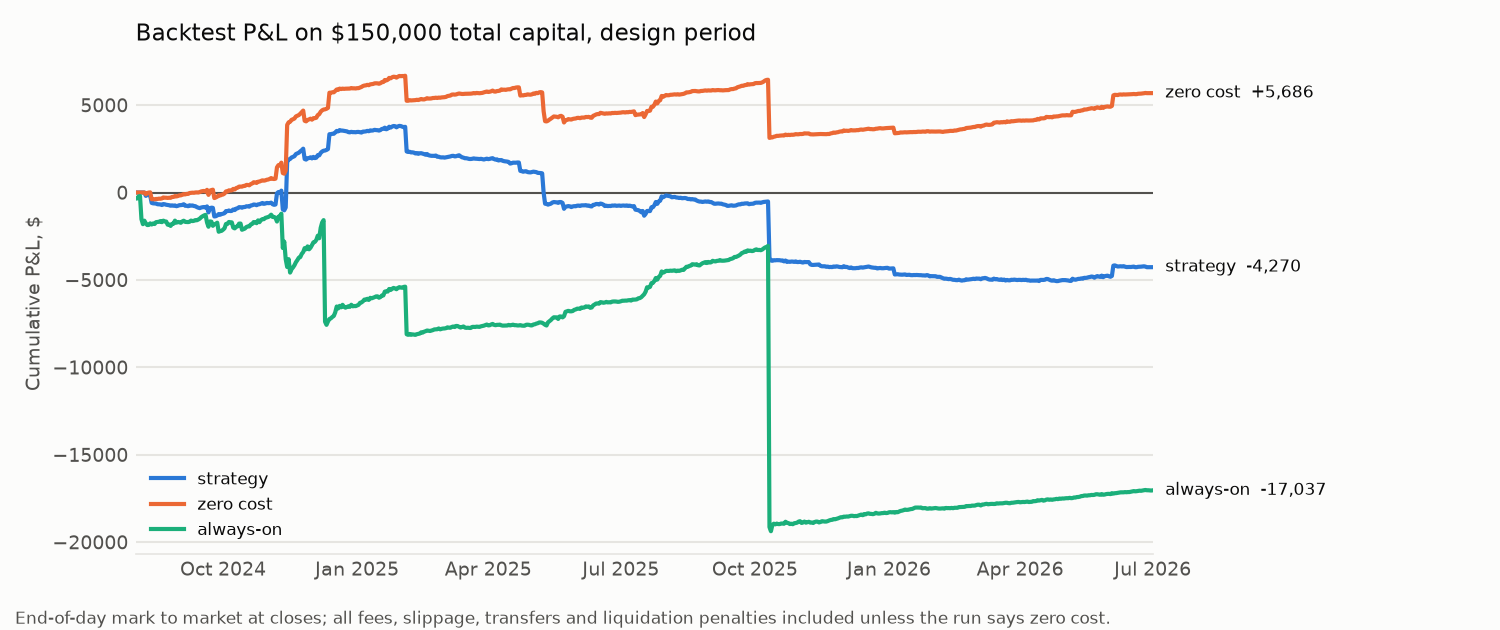

In [7]:
c = runs["corrected"]
path = ROOT / "report/figures/backtest_corrected_equity.png"
show(F.plot_equity({"strategy": c["strategy"].daily, "zero cost": c["zero_cost"].daily,
               "always-on": c["always_on"].daily}, c["strategy"].capital,
              path), path)

## 4. How trades end

Exit reasons per coin in each variant. A liquidation closes one leg at its liquidation price less
the 100 bps penalty; the other leg closes as a taker at the next bar open.

In [8]:
def reasons(r):
    t = r.trades
    out = pd.crosstab(t["coin"], t["exit_reason"]).reindex(base_cfg["universe"]["coins"]).fillna(0).astype(int)
    out["rebalances"] = t.groupby("coin")["n_rebalances"].sum().reindex(out.index).fillna(0).astype(int)
    return out
pd.concat({v: reasons(rr["strategy"]) for v, rr in runs.items()}, axis=1)

as_specified                                                 \
exit_reason   below_exit liquidation open_at_end sign_change rebalances   
coin                                                                      
BTC                    7           0           0           0          1   
ETH                    8           0           0           0          4   
SOL                   10           1           0           1         18   
kPEPE                 13           4           1           0         20   
SUI                   12           4           0           0         19   
WIF                   10           7           0           0         12   
TIA                   13           4           0           0         13   
DOGE                   7           2           0           0         13   
WLD                   15           5           0           0         15   
AAVE                   7           3           0           0         20   
APT                   15           3           0           1         15   
kBONK                 13           4           0           0          9   
AVAX                  15           2           0           0         11   
TAO                   11           6           0           0         21   
BNB                   10           0           0           0          5   

             corrected                                                 
exit_reason below_exit liquidation open_at_end sign_change rebalances  
coin                                                                   
BTC                  7           0           0           0          3  
ETH                  8           0           0           0          5  
SOL                 11           1           0           0         54  
kPEPE               13           4           1           0         31  
SUI                 13           3           0           0         27  
WIF                 11           6           0           0         15  
TIA                 15           2           0           0         13  
DOGE                 7           2           0           0         16  
WLD                 15           5           0           0         31  
AAVE                 9           1           0           0         36  
APT                 16           2           0           1         15  
kBONK               13           4           0           0         24  
AVAX                15           2           0           0         14  
TAO                 11           6           0           0         22  
BNB                 10           0           0           0          7

### Liquidated trades against the rest (strategy)

In [9]:
def by_end(r):
    t = r.trades.assign(ended=lambda x: x["exit_reason"].where(x["exit_reason"] == "liquidation", "other"))
    g = t.groupby("ended")[E.COMPONENTS + ["total"]].sum()
    g["trades"] = t.groupby("ended").size()
    return g
pd.concat({v: by_end(rr["strategy"]) for v, rr in runs.items()}).style.format(usd)

## 5. Sanity checks

Components sum to each trade's total and to the final equity; fills happen only at bar starts;
Hyperliquid funding is booked for exactly the hours held (liquidated trades excluded); counts of
missing funding hours (booked as zero), deferred fills, and mark-price fallbacks (a liquidation
check that had to use the trade candle because the mark was missing).

In [10]:
pd.DataFrame({(v, k): M.sanity(r, inputs) for v, rr in runs.items() for k, r in rr.items()})

as_specified                              \
                                 strategy     zero_cost     always_on   
missing_hl_funding           7.000000e+00  7.000000e+00  3.000000e+01   
missing_bn_funding           0.000000e+00  0.000000e+00  0.000000e+00   
deferred_fills               0.000000e+00  0.000000e+00  0.000000e+00   
liquidations                 4.500000e+01  4.500000e+01  5.700000e+01   
rebalances                   1.960000e+02  1.880000e+02  3.290000e+02   
rebalance_no_surplus         0.000000e+00  0.000000e+00  0.000000e+00   
spread_stops                 0.000000e+00  0.000000e+00  0.000000e+00   
mark_fallbacks               0.000000e+00  0.000000e+00  0.000000e+00   
max_abs_component_sum_error  0.000000e+00  0.000000e+00  0.000000e+00   
equity_vs_trades_error       1.127773e-10  1.000444e-11  6.493792e-10   
fills_off_bar_start          0.000000e+00  0.000000e+00  0.000000e+00   
hl_hours_mismatch            0.000000e+00  0.000000e+00  0.000000e+00   

                                corrected                              
                                 strategy     zero_cost     always_on  
missing_hl_funding           7.000000e+00  7.000000e+00  3.000000e+01  
missing_bn_funding           0.000000e+00  0.000000e+00  0.000000e+00  
deferred_fills               0.000000e+00  0.000000e+00  0.000000e+00  
liquidations                 3.800000e+01  3.700000e+01  6.000000e+01  
rebalances                   3.130000e+02  3.150000e+02  5.570000e+02  
rebalance_no_surplus         0.000000e+00  0.000000e+00  0.000000e+00  
spread_stops                 0.000000e+00  0.000000e+00  0.000000e+00  
mark_fallbacks               0.000000e+00  0.000000e+00  0.000000e+00  
max_abs_component_sum_error  0.000000e+00  0.000000e+00  0.000000e+00  
equity_vs_trades_error       1.755325e-10  1.800800e-10  6.402843e-10  
fills_off_bar_start          0.000000e+00  0.000000e+00  0.000000e+00  
hl_hours_mismatch            0.000000e+00  0.000000e+00  0.000000e+00